# Basic Outline of the Model:
This model extracts features using wavelet transform to capture frequency decomposition and PNCC.
The extracted features are normalized and combined into a unified vector model architecture incorporates convolutional layers, residual connections, multi-head attention, and GRUs to capture spatial, temporal, and sequential dependencies in audio.

1. **Average training accuracy:** ~72%
2. **Average validation accuracy:** ~68%
3. **Average Total Accuracy** = 70%



In [ ]:
# Importing required libraries for data processing, feature extraction, model building, and evaluation
import numpy as np
import pandas as pd
import torch
import torchaudio
import pywt
import scipy
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, Add, Dense, Dropout,
                                     BatchNormalization, GRU, MultiHeadAttention, LayerNormalization)
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import librosa

# For Google Colab integration to save/load files from Google Drive.
from google.colab import drive

# Mount Google Drive to access project files stored in the user's Drive.
drive.mount('/content/drive')


# Defining constants for file paths, audio properties, and sample length
AUDIO_PATH = '/content/drive/My Drive/Final_Project/Audio_Detection/ENGR299/ASVspoof2021_DF_eval/Sample_Audio/'
LABEL_FILE = "/content/drive/My Drive/Final_Project/Audio_Detection/ENGR299/ASVspoof2021_DF_eval/output_file.csv"
SAMPLE_RATE = 16000  # Sampling rate of audio (16 kHz)
DURATION = 2  # Duration of each audio sample in seconds
SAMPLES_PER_TRACK = SAMPLE_RATE * DURATION  # Total samples per audio track


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Function to perform data augmentation by stretching, pitch shifting, and adding noise
def augment_audio_signal(signal):
    stretched = librosa.effects.time_stretch(signal, rate=np.random.uniform(0.8, 1.2))  # Stretching the audio
    pitched = librosa.effects.pitch_shift(stretched, sr=SAMPLE_RATE, n_steps=np.random.randint(-2, 3))  # Pitch shifting
    noise = np.random.normal(0, 0.01, pitched.shape)  # Adding Gaussian noise
    return pitched + noise


In [ ]:
# Function to extract wavelet transform features
def wavelet_transform_features(signal, wavelet='db4', level=5):
    coeffs = pywt.wavedec(signal, wavelet, level=level)  # Wavelet decomposition
    wavelet_features = np.concatenate([np.array([np.mean(np.abs(c))]) if c.size > 0 else np.array([0]) for c in coeffs])
    return wavelet_features

# Function to calculate PNCC (Power-Normalized Cepstral Coefficients) features
def pncc_features(signal, sr=16000, n_fft=512, winlen=0.020, winstep=0.010, n_mels=128, power=2):
    pre_emphasis_signal = scipy.signal.lfilter([1.0, -0.97], 1, signal)  # Apply pre-emphasis filter
    stft_pre_emphasis_signal = np.abs(librosa.stft(pre_emphasis_signal, n_fft=n_fft, hop_length=int(sr * winstep),
                                                   win_length=int(sr * winlen), center=False)) ** power
    mel_filter = librosa.filters.mel(sr=sr, n_fft=n_fft, n_mels=n_mels) ** power  # Mel filter bank
    pncc_features = np.mean(np.dot(stft_pre_emphasis_signal.T, mel_filter.T) ** (1 / 15.0), axis=0)
    return pncc_features

# Function to extract combined features (Wavelet and PNCC) from an audio file
def extract_features(audio_path, augment=False):
    try:
        signal, _ = librosa.load(audio_path, sr=SAMPLE_RATE)  # Load audio signal
        if augment:
            signal = augment_audio_signal(signal)  # Apply augmentation
        signal = signal[:SAMPLES_PER_TRACK] if len(signal) > SAMPLES_PER_TRACK else np.pad(signal, (0, max(0, SAMPLES_PER_TRACK - len(signal))), 'constant')

        # Extract wavelet and PNCC features
        wavelet_feat = wavelet_transform_features(signal)
        pncc_feat = pncc_features(signal)
        features = np.concatenate([wavelet_feat, pncc_feat])  # Combine features
        return features
    except Exception as e:
        print(f"Error loading file {audio_path}: {e}")
        return None


In [ ]:
# Function to load data from a CSV file and extract features
def load_data_from_csv(augment=False):
    data = pd.read_csv(LABEL_FILE)  # Read the label file
    X, y = [], []  # Initialize feature and label lists

    for _, row in data.iterrows():
        file_path = AUDIO_PATH + row['filename']  # Full path to the audio file
        label = row['label']  # Label (bonafide/spoof)

        features = extract_features(file_path, augment=augment)  # Extract features
        if features is not None:
            X.append(features)  # Append features
            y.append(1 if label == 'spoof' else 0)  # Convert label to binary (0 or 1)

    X = np.array(X)  # Convert to numpy array
    y = np.array(y)  # Convert to numpy array
    print("Data loaded with shape:", X.shape, y.shape)
    return X, y


In [ ]:
# Function to define the model architecture for audio classification
def build_advanced_audio_model(input_shape):
    input_layer = Input(shape=input_shape)  # Input layer

    # First convolutional block with residual connection
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(input_layer)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    residual = Conv1D(64, kernel_size=1, padding='same')(input_layer)
    residual = BatchNormalization()(residual)
    residual = MaxPooling1D(pool_size=2)(residual)
    x = Add()([x, residual])  # Add residual connection

    # Second convolutional block with attention
    residual = Conv1D(128, kernel_size=1, padding='same')(x)
    residual = MaxPooling1D(pool_size=2)(residual)
    x = Conv1D(128, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = Add()([x, residual])

    # Add attention and GRU layers
    x = LayerNormalization(epsilon=1e-6)(x)
    attention_output = MultiHeadAttention(num_heads=4, key_dim=128)(x, x)
    x = Add()([x, attention_output])
    x = LayerNormalization(epsilon=1e-6)(x)
    x = GRU(128, return_sequences=True)(x)
    x = GRU(64)(x)

    # Fully connected layers with dropout
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.7)(x)
    output_layer = Dense(1, activation='sigmoid')(x)  # Output layer

    model = Model(inputs=input_layer, outputs=output_layer)
    model.compile(optimi```zer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])  # Compile the model
    return model


In [ ]:
# Load data and split into training and testing sets
X, y = load_data_from_csv(augment=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Reshape data for model input
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

# Build and train the model
input_shape = (X_train.shape[1], 1)
audio_classification_model = build_advanced_audio_model(input_shape)
training_history = audio_classification_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)]
)


Data loaded with shape: (2462, 134) (2462,)
Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.5221 - loss: 0.7318 - val_accuracy: 0.5152 - val_loss: 0.6963 - learning_rate: 1.0000e-04
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 32s 789ms/step - accuracy: 0.6302 - loss: 0.6473 - val_accuracy: 0.5152 - val_loss: 0.7084 - learning_rate: 1.0000e-04
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 22s 904ms/step - accuracy: 0.6685 - loss: 0.6265 - val_accuracy: 0.5193 - val_loss: 0.6905 - learning_rate: 1.0000e-04
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 854ms/step - accuracy: 0.7026 - loss: 0.5996 - val_accuracy: 0.5781 - val_loss: 0.6801 - learning_rate: 1.0000e-04
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 860ms/step - accuracy: 0.7055 - loss: 0.5840 - val_accuracy: 0.5477 - val_loss: 0.6720 - learning_rate: 1.0000e-04
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7034 - loss: 0.5838 - val_accuracy: 0.6978 - val_loss: 0.6670 - learning_rate: 1.0000e-04
Epoch 7/100
16

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step
              precision    recall  f1-score   support

    Bonafide       0.80      0.60      0.68       254
       Spoof       0.66      0.84      0.74       239

    accuracy                           0.71       493
   macro avg       0.73      0.72      0.71       493
weighted avg       0.73      0.71      0.71       493



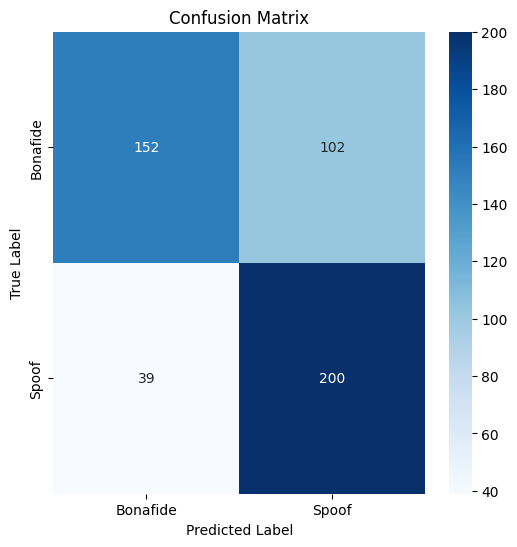

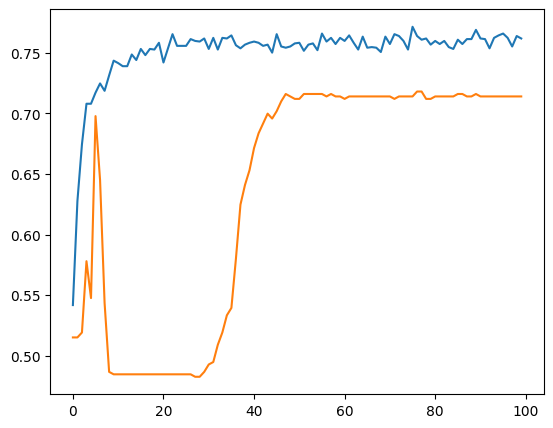

In [ ]:
# Evaluate the model on the test set and generate predictions
y_pred = (audio_classification_model.predict(X_test) > 0.5).astype("int32")
print(classification_report(y_test, y_pred, target_names=['Bonafide', 'Spoof']))

# Plot confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['Bonafide', 'Spoof'], yticklabels=['Bonafide', 'Spoof'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

# Plot training and validation performance
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(training_history.history['accuracy'], label='Training Accuracy')
plt.plot(training_history.history['val_accuracy'], label='Validation Accuracy')

# Basic Outline of the Model:
This model extracts features using STFT for time-frequency representation, **PNCC for auditory-based robustness**, and **MFCC (with delta and delta-delta coefficients)** for capturing the spectral envelope and temporal dynamics. The diverse feature set ensures comprehensive audio representation. The model architecture employs convolutional layers for spatial features and GRUs for sequential dependencies.



1.  **Training Accuracy:**  ~65%.
2.  **Validation Accuracy:**  ~67.5%.
3. **Average Total Accuracy** ≈ 59.5%




Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.5200 - loss: 0.8700 - val_accuracy: 0.5181 - val_loss: 0.6936 - learning_rate: 1.0000e-04
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.5214 - loss: 0.8380 - val_accuracy: 0.5221 - val_loss: 0.6898 - learning_rate: 1.0000e-04
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.5371 - loss: 0.8122 - val_accuracy: 0.5382 - val_loss: 0.6987 - learning_rate: 1.0000e-04
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.5318 - loss: 0.8069 - val_accuracy: 0.5382 - val_loss: 0.7045 - learning_rate: 1.0000e-04
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.5549 - loss: 0.7891 - val_accuracy: 0.5382 - val_loss: 0.7081 - learning_rate: 1.0000e-04
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.5648 - loss: 0.7895 - val_accuracy: 0.5382 - val_loss: 0.7069 - learning_rate: 1.0000e-04
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.5836 

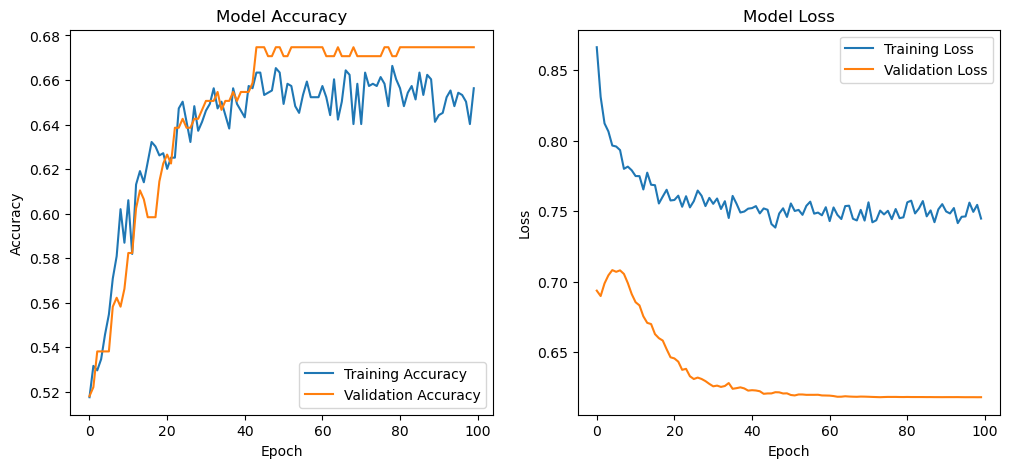

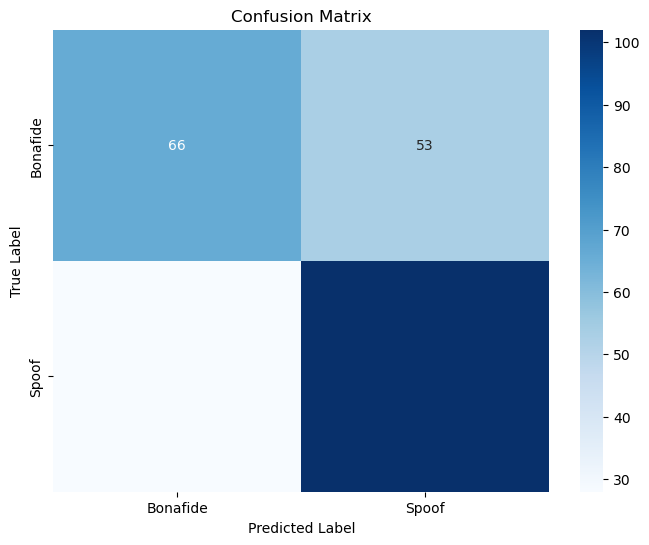

In [ ]:
import numpy as np
import pandas as pd
import librosa
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.layers import Conv1D, MaxPooling1D, BatchNormalization, Dense, Dropout, Flatten, Input, Add, GRU
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau
import matplotlib.pyplot as plt
import seaborn as sns

# Constants
AUDIO_PATH = '/Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/Sample_Audio/'
LABEL_FILE = '/Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/output_file.csv'
SAMPLE_RATE = 16000
DURATION = 2  # seconds
SAMPLES_PER_TRACK = SAMPLE_RATE * DURATION

# Function to augment data with pitch shift and noise
def augment_audio(signal):
    pitch_shifted = librosa.effects.pitch_shift(signal, sr=SAMPLE_RATE, n_steps=2)
    noise = np.random.normal(0, 0.005, len(signal))
    signal_noisy = signal + noise
    return [signal, pitch_shifted, signal_noisy]

# Extract STFT, PNCC, MFCC with delta coefficients
def extract_features(file_path, augment=False):
    try:
        signal, _ = librosa.load(file_path, sr=SAMPLE_RATE, duration=DURATION)
        if len(signal) < SAMPLES_PER_TRACK:
            signal = np.pad(signal, (0, SAMPLES_PER_TRACK - len(signal)))

        features = []
        if augment:
            signals = augment_audio(signal)
        else:
            signals = [signal]

        for s in signals:
            # Ensure the signal has content
            if np.sum(np.abs(s)) == 0:
                print(f"Empty or silent audio file: {file_path}")
                return None

            # STFT
            stft = np.abs(librosa.stft(s))
            stft_mean = np.mean(stft, axis=1)
            stft_std = np.std(stft, axis=1)

            # PNCC placeholder (using MFCC as a temporary substitute)
            pncc = librosa.feature.mfcc(y=s, sr=SAMPLE_RATE, n_mfcc=13)
            pncc_mean = np.mean(pncc, axis=1)
            pncc_std = np.std(pncc, axis=1)

            # MFCC and delta features
            mfcc = librosa.feature.mfcc(y=s, sr=SAMPLE_RATE, n_mfcc=13)
            delta_mfcc = librosa.feature.delta(mfcc)
            delta2_mfcc = librosa.feature.delta(mfcc, order=2)

            # Aggregate features
            mfcc_features = np.concatenate((np.mean(mfcc, axis=1), np.std(mfcc, axis=1),
                                            np.mean(delta_mfcc, axis=1), np.std(delta_mfcc, axis=1),
                                            np.mean(delta2_mfcc, axis=1), np.std(delta2_mfcc, axis=1)))
            features.extend(np.concatenate([stft_mean, stft_std, pncc_mean, pncc_std, mfcc_features]))

        return np.array(features)
    except Exception as e:
        print(f"Failed to extract features from file: {file_path}. Error: {str(e)}")
        return None

# Load data and apply feature extraction
def load_data_from_csv(augment=False):
    data = pd.read_csv(LABEL_FILE)
    X, y = [], []
    for _, row in data.iterrows():
        file_path = AUDIO_PATH + row['filename']
        label = 1 if row['label'] == 'spoof' else 0
        features = extract_features(file_path, augment=augment)
        if features is not None:
            X.append(features)
            y.append(label)
    return np.array(X), np.array(y)

# Define model architecture
def build_advanced_audio_model(input_shape):
    input_layer = Input(shape=input_shape)

    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(input_layer)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.3)(x)

    x = Conv1D(128, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.3)(x)

    x = GRU(64, return_sequences=True)(x)
    x = GRU(64)(x)

    x = Dense(64, activation='relu')(x)
    x = Dropout(0.3)(x)
    output_layer = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=input_layer, outputs=output_layer)
    model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Load Data
X, y = load_data_from_csv(augment=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

# Define class weights
class_weights = {0: 1.0, 1: 1.5}

# Model Training
input_shape = (X_train.shape[1], 1)
audio_classification_model = build_advanced_audio_model(input_shape)
training_history = audio_classification_model.fit(
    X_train, y_train,
    epochs=100,
    validation_data=(X_test, y_test),
    class_weight=class_weights,
    batch_size=,
    callbacks=[ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)]
)

# Model Evaluation
y_pred = (audio_classification_model.predict(X_test) > 0.5).astype("int32")
print(classification_report(y_test, y_pred, target_names=['Bonafide', 'Spoof']))

# Plotting training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(training_history.history['accuracy'], label='Training Accuracy')
plt.plot(training_history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Model Accuracy')

plt.subplot(1, 2, 2)
plt.plot(training_history.history['loss'], label='Training Loss')
plt.plot(training_history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Model Loss')
plt.show()

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['Bonafide', 'Spoof'], yticklabels=['Bonafide', 'Spoof'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()
